In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('/content/Unemployment in India.csv')

df.head()

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


In [3]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (768, 7)

Column Names:
['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Area']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Region                                    740 non-null    object 
 1    Date                                     740 non-null    object 
 2    Frequency                                740 non-null    object 
 3    Estimated Unemployment Rate (%)          740 non-null    float64
 4    Estimated Employed                       740 non-null    float64
 5    Estimated Labour Participation Rate (%)  740 non-null    float64
 6   Area                                      740 non-null    object 
dtypes: float64(3), object(4)
memory usage: 42.1+ K

In [4]:
# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Convert the Date column into date format
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True, errors='coerce')

# Remove duplicate rows
df = df.drop_duplicates()

# Check missing values
print("Missing values before cleaning:")
print(df.isnull().sum())

# Display the cleaned dataset
df.head()

Missing values before cleaning:
Region                                     1
Date                                       1
Frequency                                  1
Estimated Unemployment Rate (%)            1
Estimated Employed                         1
Estimated Labour Participation Rate (%)    1
Area                                       1
dtype: int64


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,2019-05-31,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,2019-06-30,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,2019-07-31,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,2019-08-31,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,2019-09-30,Monthly,5.17,12256762.0,44.68,Rural


In [5]:
# Basic statistical analysis
print("Dataset Information:")
print(df.info())

print("\nUnemployment Rate Statistics:")
print(df['Estimated Unemployment Rate (%)'].describe())

print("\nAverage Unemployment Rate by Region:")
print(
    df.groupby('Region')['Estimated Unemployment Rate (%)']
    .mean()
    .sort_values(ascending=False)
)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
Index: 741 entries, 0 to 753
Data columns (total 7 columns):
 #   Column                                   Non-Null Count  Dtype         
---  ------                                   --------------  -----         
 0   Region                                   740 non-null    object        
 1   Date                                     740 non-null    datetime64[ns]
 2   Frequency                                740 non-null    object        
 3   Estimated Unemployment Rate (%)          740 non-null    float64       
 4   Estimated Employed                       740 non-null    float64       
 5   Estimated Labour Participation Rate (%)  740 non-null    float64       
 6   Area                                     740 non-null    object        
dtypes: datetime64[ns](1), float64(3), object(3)
memory usage: 46.3+ KB
None

Unemployment Rate Statistics:
count    740.000000
mean      11.787946
std       10.721298
min        0.000000

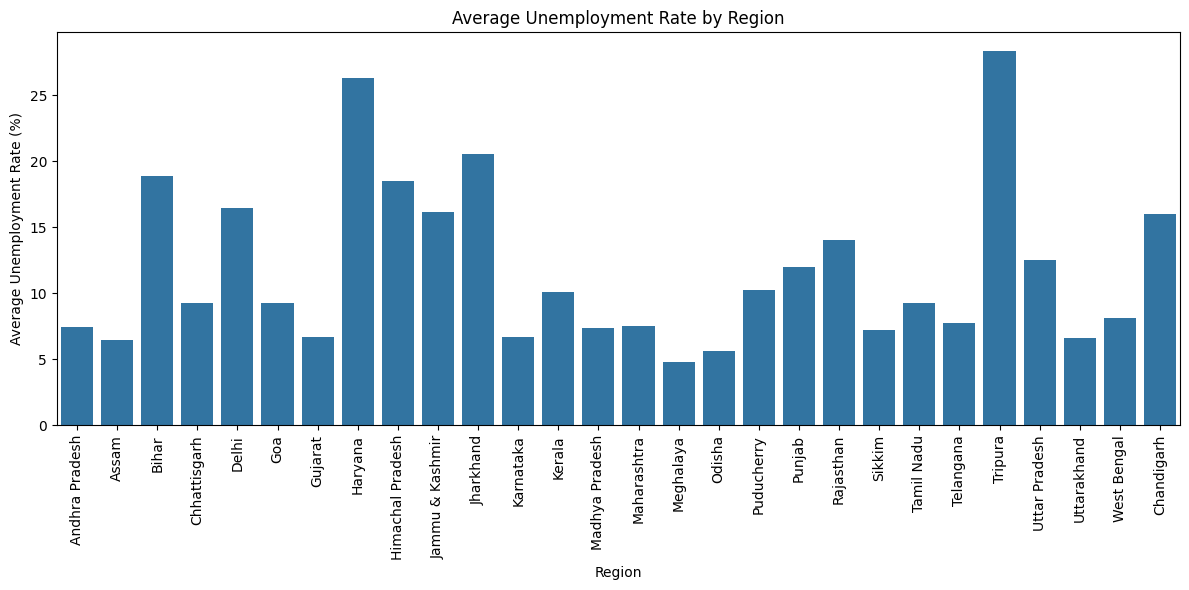

In [6]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=df,
    x='Region',
    y='Estimated Unemployment Rate (%)',
    errorbar=None
)

plt.title('Average Unemployment Rate by Region')
plt.xlabel('Region')
plt.ylabel('Average Unemployment Rate (%)')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

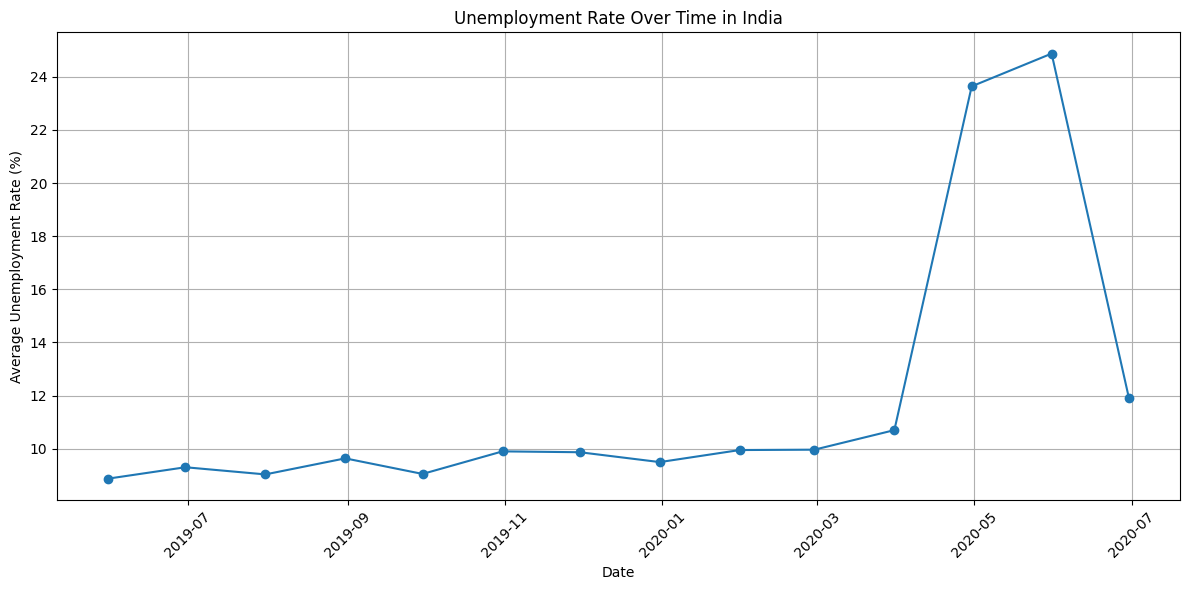

In [7]:
# Average unemployment rate over time
time_data = df.groupby('Date')['Estimated Unemployment Rate (%)'].mean()

plt.figure(figsize=(12, 6))
plt.plot(time_data.index, time_data.values, marker='o')

plt.title('Unemployment Rate Over Time in India')
plt.xlabel('Date')
plt.ylabel('Average Unemployment Rate (%)')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

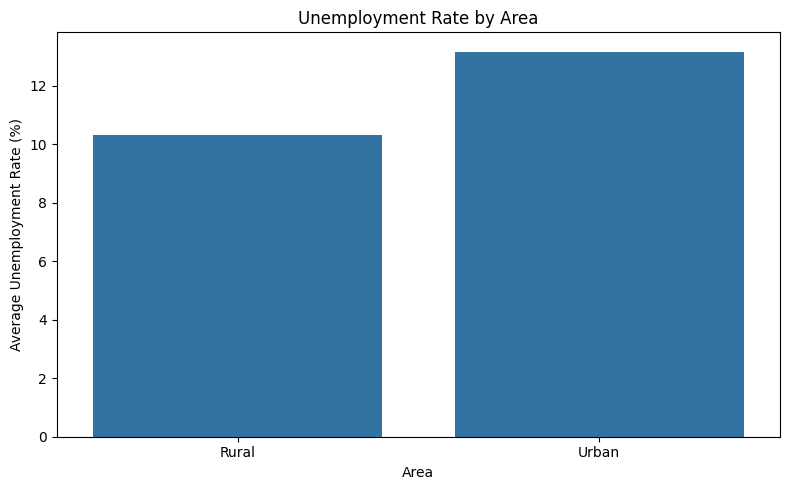

In [8]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x='Area',
    y='Estimated Unemployment Rate (%)',
    errorbar=None
)

plt.title('Unemployment Rate by Area')
plt.xlabel('Area')
plt.ylabel('Average Unemployment Rate (%)')
plt.tight_layout()
plt.show()

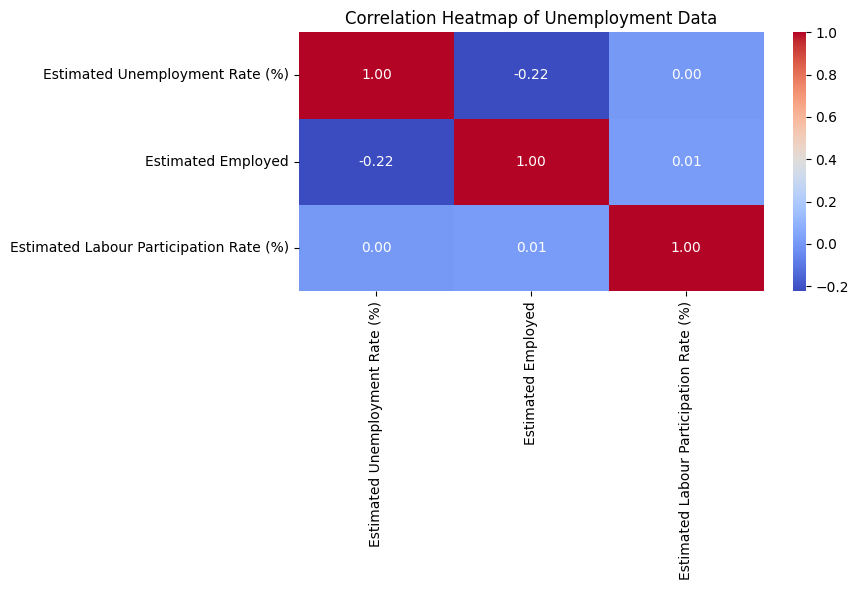

In [9]:
numeric_df = df.select_dtypes(include='number')

plt.figure(figsize=(9, 6))
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Heatmap of Unemployment Data')
plt.tight_layout()
plt.show()

In [10]:
# 1. Overall average unemployment rate
overall_rate = df['Estimated Unemployment Rate (%)'].mean()
print(f"Overall Average Unemployment Rate: {overall_rate:.2f}%")

# 2. Region with the highest average unemployment rate
region_rates = df.groupby('Region')['Estimated Unemployment Rate (%)'].mean()

print("\nRegion with Highest Average Unemployment Rate:")
print(region_rates.idxmax(), "-", round(region_rates.max(), 2), "%")

# 3. Region with the lowest average unemployment rate
print("\nRegion with Lowest Average Unemployment Rate:")
print(region_rates.idxmin(), "-", round(region_rates.min(), 2), "%")

# 4. Compare urban and rural unemployment
print("\nAverage Unemployment Rate by Area:")
print(df.groupby('Area')['Estimated Unemployment Rate (%)'].mean().round(2))

Overall Average Unemployment Rate: 11.79%

Region with Highest Average Unemployment Rate:
Tripura - 28.35 %

Region with Lowest Average Unemployment Rate:
Meghalaya - 4.8 %

Average Unemployment Rate by Area:
Area
Rural    10.32
Urban    13.17
Name: Estimated Unemployment Rate (%), dtype: float64


In [ ]:
The Unemployment Analysis project uses Python to explore unemployment trends in India.
The dataset was cleaned and analyzed to understand unemployment rates across different regions and areas.
Data visualization was used to compare unemployment rates and examine changes over time.
The analysis helps identify regional differences and patterns in unemployment data.
This project helped me learn data cleaning, exploratory data analysis (EDA), statistical analysis, and data visualization using Python.
Important: Your final conclusion should reflect the actual results produced by your notebook. Avoid claiming a specific trend unless your graphs support it.